In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import os

# Load 5k_oct

In [4]:
"""
Put path to the directory with your files here
"""
base_dir='/nfs/team298/beacon_ls34/'
[x for x in os.listdir(base_dir)] 

['20240409_run1_skin_nosegmentation',
 '20260129_SGP312_5K_BCN\uf028',
 'BK25-3D_A1 HnE',
 'BCN_FFPE_test',
 '20260413_SGP331_5K_ESTOP',
 '20240711__110557__SGP174_SKI_run1_skin segmented',
 '.ipynb_checkpoints',
 'adata_xeniumimmunooncology_processed.h5ad',
 'MH_BCN_X0072771 - 2026-04-28 10.51.58.ndpi',
 '20240815__115640__SGP177_SKI_run1',
 'MH_BCN_X0072869 - 2026-04-28 10.45.23.ndpi',
 '3D NPDI files',
 'paths_all2.csv',
 'loaded_adatas',
 '20241107__113135__SGP205_SKI_run1',
 'adata_5k_oct_aug.h5ad.addedmetadata.integrated.annotatedfbsannotated.t.myeloid.kc.nichecompass',
 '20240624__145030_immunoncologypanel_segmented',
 'H&Es 07112024',
 '20241217_SGP212_5K_HS',
 '20251204_SGP304_run1_Mintflow revision',
 '20240628__123954__AF_ECZ5K_human_skin_BEACON_1',
 '20250227_SGP218_5K_CTCL only',
 '20241010__132615__SGP194_SKI_RUN1',
 'visium_pilot',
 'SGP303_HaniffaLotfollahi_Embryo_WEM',
 'paths_all.csv',
 'adata_5k_oct_aug.h5ad.addedmetadata.integrated.annotatedfbsannotated.t.myeloid.kc

In [10]:
"""
test that a file seems corrects
the list above should just be paths to xenium data - no other files
"""
RUN_ID = '20241217_SGP212_5K_HS/'
print(base_dir+RUN_ID)
os.listdir(base_dir+RUN_ID)

/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS/


['output-XETG00155__0032957__AX39-SKI-0-FO-2-S3-C2__20241217__145711',
 'output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711',
 'output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049',
 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00155__0032945__AX36-SKI-0-FO-2-S3-C2__20241217__145711',
 'Post-Xenium H&Es',
 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
 'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
 'output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711',
 'output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049',
 'output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049',
 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',
 'output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
 'combin

In [13]:
KEEP = ['output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',     
'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711'    ,
'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049'      ,
'output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711'    ,
'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049'       ,
'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049'        ,
'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711'   ,
'output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711',
       ]
for SAMPLE in KEEP:
    NEW_PATH=base_dir+RUN_ID+"/"+SAMPLE
    #print()
    #print(os.listdir(NEW_PATH))
    print(NEW_PATH)

/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711
/nfs/team298/beacon_ls34/20241217_SGP212_5K_HS//output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711


In [ ]:
for

In [ ]:
 '20241217_SGP212_5K_HS/'

In [4]:
"""
load adatas
"""

adatas_dict = {}
for sample_id in os.listdir(base_dir + RUN_ID):
    print(sample_id)
    new_path = base_dir + RUN_ID + sample_id
    if sample_id.startswith("output"):
        if len(os.listdir(new_path))>0:
            print(f"New path: {new_path}")

            print(os.listdir(new_path))
            print(" ")
            adata = sc.read_10x_h5(filename=new_path+"/cell_feature_matrix.h5")
            df = pd.read_csv(new_path+"/cells.csv.gz")
            df.set_index(adata.obs_names, inplace=True)
            adata.obs = df.copy()
            adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].copy().to_numpy()
            adata.obs["sample_id"]=sample_id.split("__")[2]
            adata.obs["sample_id_dir"]=sample_id
            adata.obs["patient_id"]=sample_id.split("__")[2][:4]

            adatas_dict[sample_id] = adata
            
            print(adata)
            print()
        else:
            print("###EMPTY SAMPLE: ", sample_id)
adata = ad.concat(adatas_dict.values(), join='outer', label='sample_id', keys=list(adatas_dict.keys()))
del(adatas_dict)

output-XETG00155__0032957__AX39-SKI-0-FO-2-S3-C2__20241217__145711
New path: /nfs/team298/beacon_ls34/20241217_SGP212_5K_HS/output-XETG00155__0032957__AX39-SKI-0-FO-2-S3-C2__20241217__145711
['experiment.xenium', 'gene_panel.json', 'analysis.zarr.zip', 'cells.csv.gz', 'cells.zarr.zip', 'cell_boundaries.csv.gz', 'metrics_summary.csv', 'aux_outputs', 'cell_feature_matrix.h5', 'transcripts.zarr.zip', 'transcripts.parquet', '.end-of-run', 'cell_boundaries.parquet', 'nucleus_boundaries.parquet', 'analysis_summary.html', 'morphology.ome.tif', 'cells.parquet', 'cell_feature_matrix', 'analysis', 'cell_feature_matrix.zarr.zip', 'nucleus_boundaries.csv.gz', 'morphology_focus']
 
AnnData object with n_obs × n_vars = 5843 × 5001
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segm

/software/cellgen/team298/ls34/scpoli/lib/python3.11/site-packages/anndata/_core/anndata.py:1818: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [5]:
adata.obs["sample_id"].value_counts()


sample_id
output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049       48801
output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049      45612
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       43657
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       42161
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    39389
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    30579
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    17339
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       16290
output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049       15569
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       15532
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    13759
output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049       13139
output-XETG00272__0021042__AX33-SKI-0-FO-2-S3__20240815__114049       12655
ou

In [6]:
adata.obs["sample_id"].value_counts()


sample_id
output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049       48801
output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049      45612
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       43657
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       42161
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    39389
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    30579
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    17339
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       16290
output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049       15569
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       15532
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    13759
output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049       13139
output-XETG00272__0021042__AX33-SKI-0-FO-2-S3__20240815__114049       12655
ou

In [7]:
adata.obs["segmentation_method"].value_counts()

segmentation_method
Segmented by interior stain (18S)                       255351
Segmented by boundary stain (ATP1A1+CD45+E-Cadherin)     79045
Segmented by nucleus expansion of 5.0µm                  30292
Name: count, dtype: int64

# Transfer pre-existing laberls

In [8]:
# ADATA_5K_PATH = "/lustre/scratch126/cellgen/team298/ls34/beacon/processed_adatas/adata_xenium_5k_UPDATING2.h5ad.newnotebooks"
# adata_subset_labelled=sc.read_h5ad(ADATA_5K_PATH)
# adata_subset_labelled




In [9]:
# #adata_subset_labelled.obs.index = adata_subset_labelled.obs["cell_id"]
# mapping_dict = adata_subset_labelled.obs['annotation_working'].to_dict()

# adata.obs['celltypes2'] = "Unassigned"

# adata.obs['celltypes2'] = adata.obs.index.map(mapping_dict).fillna("Unassigned")

# adata.obs['celltypes2'].value_counts()



In [10]:
# #adata_subset_labelled.obs.index = adata_subset_labelled.obs["cell_id"]
# mapping_dict = adata_subset_labelled.obs['lvl0_annotation'].to_dict()

# adata.obs['lvl0_annotation'] = "Unassigned"

# adata.obs['lvl0_annotation'] = adata.obs.index.map(mapping_dict).fillna("Unassigned")

# adata.obs['lvl0_annotation'].value_counts()



# QC metrics

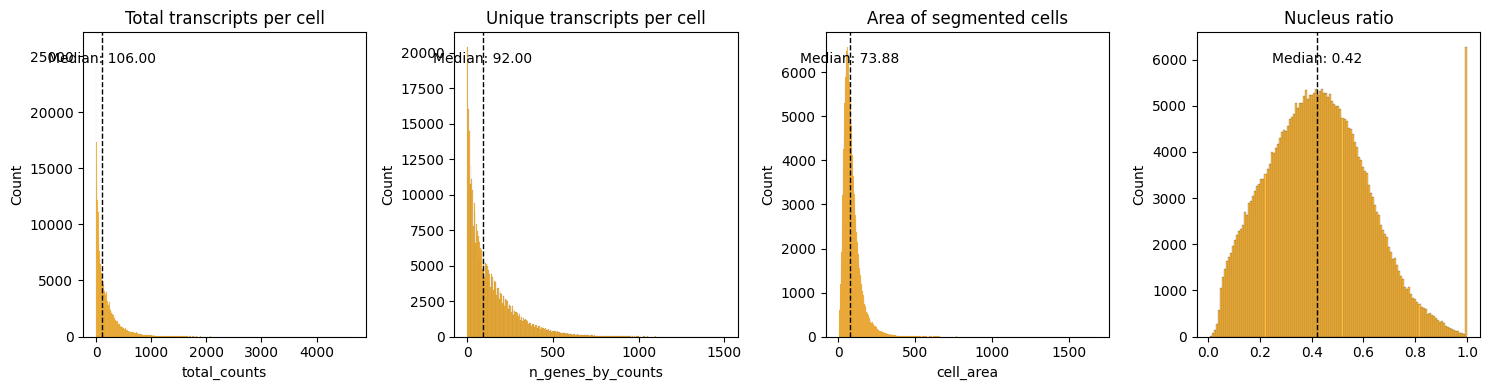

In [11]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 4, figsize=(15, 4))

def add_median_line(ax, data, color='orange'):
    median = data.median()
    ax.axvline(median, color='k', linestyle='dashed', linewidth=1)
    ax.text(median, ax.get_ylim()[1] * 0.9, f'Median: {median:.2f}', color='k', ha='center')

# Total transcripts per cell
axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
    color='orange'
)
add_median_line(axs[0], adata.obs["total_counts"])

# Unique transcripts per cell
axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
    color='orange'
)
add_median_line(axs[1], adata.obs["n_genes_by_counts"])

# Area of segmented cells
axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
    color='orange'
)
add_median_line(axs[2], adata.obs["cell_area"])

# Nucleus ratio
axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
    color='orange'
)
add_median_line(axs[3], adata.obs["nucleus_area"] / adata.obs["cell_area"])

plt.tight_layout()
plt.show()


In [12]:
cprobes = (
    adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
cwords = (
    adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

Negative DNA probe count % : 0.005381821647825448
Negative decoding count % : 0.0005245241940780201


In [13]:
"""
ONLY FILTERING IS IF <10 COUNTS INITIALLY
"""
sc.pp.filter_cells(adata, min_counts=10)
#sc.pp.filter_genes(adata, min_cells=2)

/software/cellgen/team298/ls34/scpoli/lib/python3.11/site-packages/anndata/_core/anndata.py:1818: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [14]:
"""
make unique IDs
"""
adata.obs.index = adata.obs["cell_id"].astype(str) + "_" + adata.obs["sample_id"].astype(str) 

# Look at a sample! 

In [15]:
adata.obs["sample_id"].value_counts()

sample_id
output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049       42865
output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049      39971
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       39886
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       38140
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    37476
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    28951
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    15322
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       15085
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       14551
output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049       14320
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    13311
output-XETG00272__0021042__AX33-SKI-0-FO-2-S3__20240815__114049       10842
output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049       10334
ou

In [16]:
adata.obs["sample_id"].value_counts()

sample_id
output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049       42865
output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049      39971
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       39886
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       38140
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    37476
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    28951
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    15322
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       15085
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       14551
output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049       14320
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    13311
output-XETG00272__0021042__AX33-SKI-0-FO-2-S3__20240815__114049       10842
output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049       10334
ou

/software/cellgen/team298/ls34/scpoli/lib/python3.11/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/scpoli/lib/python3.11/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/scpoli/lib/python3.11/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


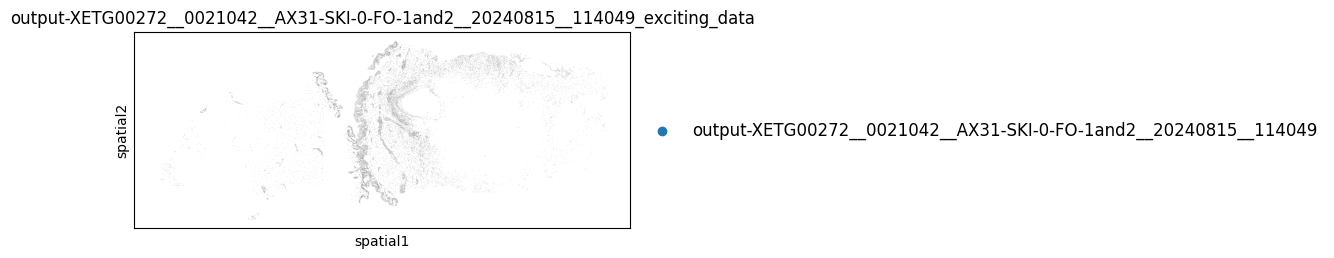

In [17]:
"""
PICK A SAMPLE FROM ABOVE
"""
SAMPLE_ID_TO_PLOT = "output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049"

sc.pl.spatial(
        adata[adata.obs["sample_id"]==SAMPLE_ID_TO_PLOT],

        color="sample_id", # need to color the cells at some point
        spot_size=1,

        title=SAMPLE_ID_TO_PLOT + "_exciting_data",

                edgecolor="black",
        linewidth=0.1,
                legend_fontsize=12,

    )

# SAVE OUTPUT

In [18]:
save_path_of_adata_here='/nfs/team361/ls34/data/adata_hs_preprocessed.h5ad'

In [19]:
adata.write(save_path_of_adata_here)
adata.obs["sample_id"].value_counts()

sample_id
output-XETG00272__0021042__AX33-SKI-0-FO-1-S3__20240815__114049       42865
output-XETG00272__0021042__AX31-SKI-0-FO-1and2__20240815__114049      39971
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       39886
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       38140
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    37476
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    28951
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    15322
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       15085
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       14551
output-XETG00272__0021175__AX32-SKI-0-FO-1-S3__20240815__114049       14320
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    13311
output-XETG00272__0021042__AX33-SKI-0-FO-2-S3__20240815__114049       10842
output-XETG00272__0021175__AX32-SKI-0-FO-2-S3__20240815__114049       10334
ou

In [20]:
adata.var

,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
A2ML1,21502,0.133947,0.125705,94.104001,48849.0,10.796510
AAMP,46889,0.167678,0.155017,87.142708,61150.0,11.021102
AAR2,2735,0.007708,0.007678,99.250044,2811.0,7.941651
AARSD1,7439,0.021298,0.021074,97.960174,7767.0,8.957768
ABAT,3570,0.010302,0.010249,99.021081,3757.0,8.231642
...,...,...,...,...,...,...
ZSCAN26,4444,0.012572,0.012494,98.781424,4585.0,8.430763
ZSWIM6,3528,0.009885,0.009837,99.032598,3605.0,8.190354
ZUP1,3653,0.010236,0.010184,98.998322,3733.0,8.225235
ZYG11B,3871,0.010823,0.010765,98.938545,3947.0,8.280965


In [21]:
#save_path_of_adata_here